In [1]:
%matplotlib inline
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    pairwise_distances,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
import umap

RANDOM_STATE = 141026
CLASS_NAMES = ["m0", "m1", "m2"]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sns.set_theme(style="whitegrid", context="notebook")
print("Device:", DEVICE)
print("Seed:", RANDOM_STATE)


/home/vnikolaieva/ML/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Seed: 141026


`cell_type` - label. 

`sample_group` is an anonymised experiment / sample id


In [2]:
DATA_PATH = Path("large_object_vgg3d_embeddings_processed.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("week6") / "large_object_vgg3d_embeddings_processed.csv"

df = pd.read_csv(DATA_PATH)
print("File:", DATA_PATH.resolve())
print("Shape (rows, columns):", df.shape)
display(df.head(3))

print("Column types:")
display(df.dtypes.value_counts().rename("columns").to_frame())

print("Class counts (how many objects of each cell type):")
display(df["cell_type"].value_counts().rename("objects").to_frame())
print("Class proportions:")
display(df["cell_type"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())

missing_cells = int(df.isna().sum().sum())
duplicate_rows = int(df.duplicated().sum())
feature_candidates = [column for column in df.columns if column.startswith("vgg_emb_")]
constant_features = [column for column in feature_candidates if df[column].nunique(dropna=False) <= 1]
usable_features = [column for column in feature_candidates if column not in constant_features]
duplicate_embeddings = int(df.duplicated(feature_candidates).sum())

print("Missing values:", missing_cells)
print("Exact duplicate rows:", duplicate_rows)
print("Duplicate embedding vectors:", duplicate_embeddings)
print("Embedding columns:", len(feature_candidates))
print("All-zero / constant embedding columns:", len(constant_features))
print("Columns kept as model inputs:", len(usable_features))
print("Feature minimum:", float(df[feature_candidates].min().min()))
print("Feature maximum:", float(df[feature_candidates].max().max()))

group_sizes = df.groupby("sample_group").size()
classes_per_group = df.groupby("sample_group")["cell_type"].nunique()
print("Sample groups:", df["sample_group"].nunique())
print("Objects per group: min", int(group_sizes.min()), "| median", float(group_sizes.median()), "| max", int(group_sizes.max()))
print("Groups that contain more than one cell type:", int((classes_per_group > 1).sum()))
print("Groups per cell type:")
display(df.groupby("cell_type")["sample_group"].nunique().rename("groups").to_frame())

# sample_group must never enter the feature matrix.
assert "sample_group" not in usable_features
assert "cell_type" not in usable_features
assert set(df["cell_type"].unique()) == set(CLASS_NAMES)


File: /home/vnikolaieva/ML/week6/large_object_vgg3d_embeddings_processed.csv
Shape (rows, columns): (381, 130)


,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0


Column types:


,columns
float64,128
str,2


Class counts (how many objects of each cell type):


,objects
cell_type,
m2,145
m0,132
m1,104


Class proportions:


,proportion
cell_type,
m0,0.346457
m1,0.272966
m2,0.380577


Missing values: 0
Exact duplicate rows: 0
Duplicate embedding vectors: 0
Embedding columns: 128
All-zero / constant embedding columns: 37
Columns kept as model inputs: 91
Feature minimum: 0.0
Feature maximum: 44.92271423339844
Sample groups: 85
Objects per group: min 1 | median 3.0 | max 22
Groups that contain more than one cell type: 0
Groups per cell type:


,groups
cell_type,
m0,19
m1,46
m2,20


- **381 objects, 128 embedding numbers.** VGG3D describes each object with a vector.
- **37 of those numbers are always 0.** That channel of the network never fired, so it has no information. Keeping it would also annoy the scaler, which divides by the standard deviation: a column of zeros has standard deviation 0. Removed.
- **No missing values and no duplicate rows.**
- **The scales are different** Needs standardization.
- **`sample_group` in metadata.** There are 85 groups. Every group contains only one cell type and a typical group has only a few objects (median 3, one group has 22). Several objects are repeated views of the same biological sample. They are not 381 independent experiments.


## Exploration


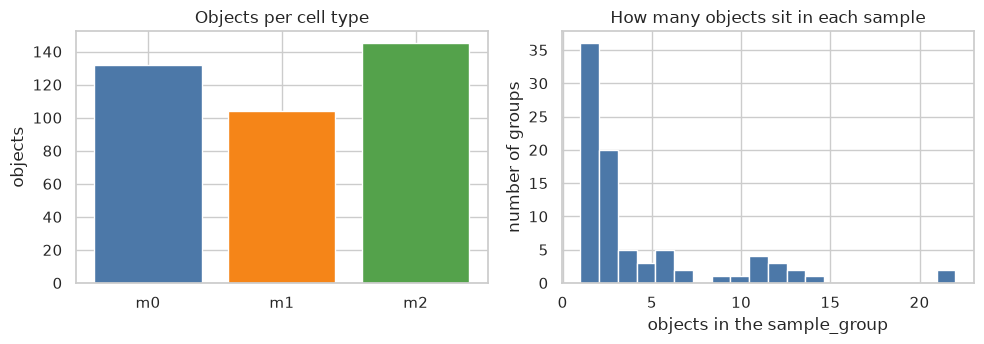

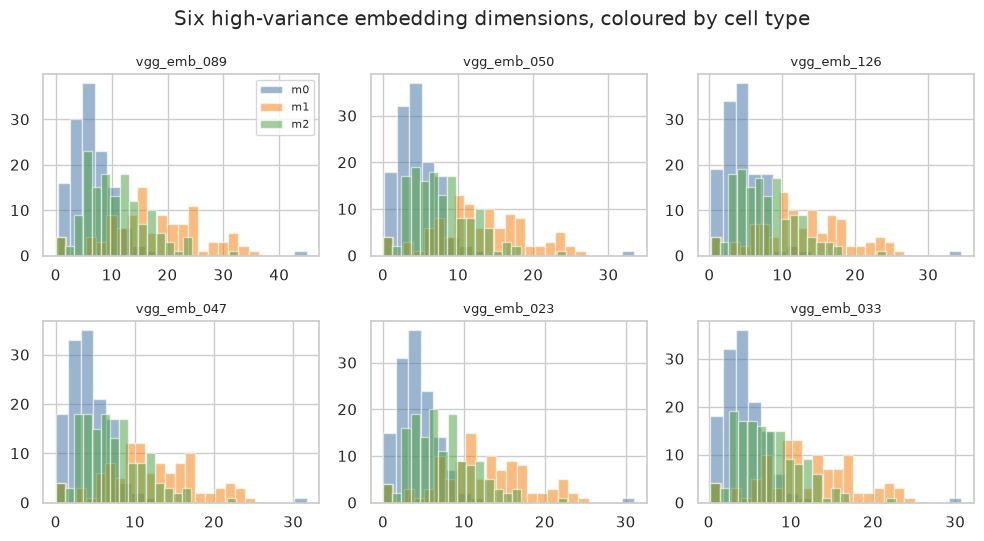

The class histograms overlap in individual dimensions. One number is not enough to name the cell type, which is why the model needs the whole vector.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
class_counts = df["cell_type"].value_counts().reindex(CLASS_NAMES)
axes[0].bar(class_counts.index, class_counts.values, color=["#4C78A8", "#F58518", "#54A24B"])
axes[0].set_title("Objects per cell type")
axes[0].set_ylabel("objects")
axes[1].hist(group_sizes, bins=20, color="#4C78A8")
axes[1].set_title("How many objects sit in each sample")
axes[1].set_xlabel("objects in the sample_group")
axes[1].set_ylabel("number of groups")
fig.tight_layout()
plt.show()

# Show the embedding dimensions that actually vary. A histogram of an all-zero
# column would be a single spike and would not teach anything.
spread = df[usable_features].var().sort_values(ascending=False)
example_features = spread.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(10, 5.5))
for axis, feature in zip(axes.ravel(), example_features):
    for class_name, color in zip(CLASS_NAMES, ["#4C78A8", "#F58518", "#54A24B"]):
        values = df.loc[df["cell_type"] == class_name, feature]
        axis.hist(values, bins=20, alpha=0.55, label=class_name, color=color)
    axis.set_title(feature, fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Six high-variance embedding dimensions, coloured by cell type")
fig.tight_layout()
plt.show()
print("The class histograms overlap in individual dimensions. One number is not enough to name the cell type, which is why the model needs the whole vector.")


## PCA, t-SNE, and UMAP

- **PCA** keeps the directions where the numbers vary most.
- **t-SNE** and **UMAP** try to keep nearby objects nearby on the plot.

/home/vnikolaieva/ML/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


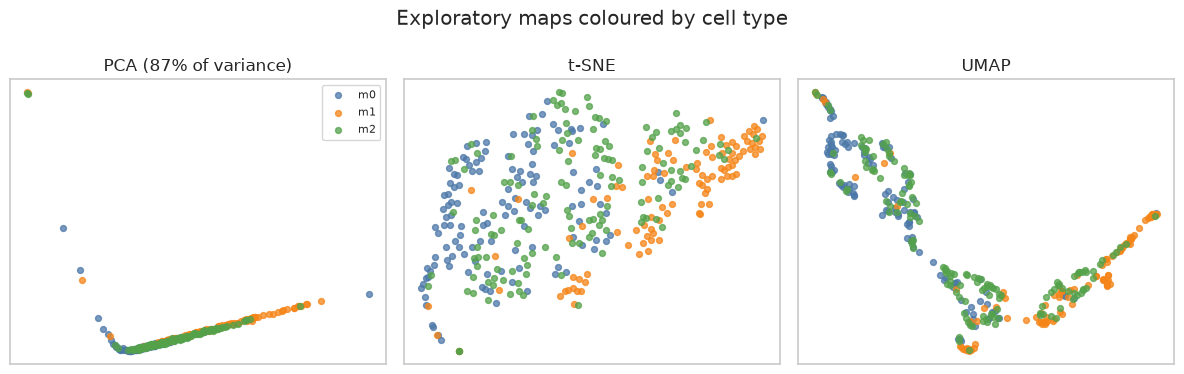

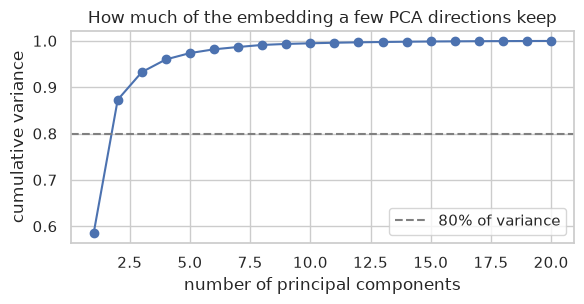

Components needed to pass 80% of the variance: 2
Mean distance, same sample_group:      6.379
Mean distance, different sample_group: 9.952
Mean distance, same cell type:         7.957
Mean distance, different cell type:    10.859


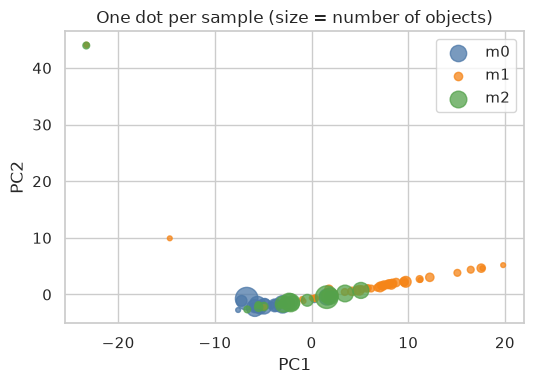

In [4]:
X_embed = df[usable_features].to_numpy(dtype=np.float64)
groups = df["sample_group"].to_numpy()
labels = df["cell_type"].to_numpy()

viz_scaler = StandardScaler()
X_viz = viz_scaler.fit_transform(X_embed)

pca_plot = PCA(n_components=2, random_state=RANDOM_STATE)
pcs2 = pca_plot.fit_transform(X_viz)
pca_var = PCA(n_components=min(20, X_viz.shape[1]), random_state=RANDOM_STATE)
pca_var.fit(X_viz)
cumulative = np.cumsum(pca_var.explained_variance_ratio_)

tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=RANDOM_STATE,
)
tsne_xy = tsne.fit_transform(X_viz)

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=RANDOM_STATE,
)
umap_xy = umap_model.fit_transform(X_viz)

colors = {"m0": "#4C78A8", "m1": "#F58518", "m2": "#54A24B"}

def scatter_by_class(axis, xy, title):
    for class_name in CLASS_NAMES:
        mask = labels == class_name
        axis.scatter(xy[mask, 0], xy[mask, 1], s=18, alpha=0.75, c=colors[class_name], label=class_name)
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
scatter_by_class(axes[0], pcs2, f"PCA ({pca_plot.explained_variance_ratio_.sum():.0%} of variance)")
scatter_by_class(axes[1], tsne_xy, "t-SNE")
scatter_by_class(axes[2], umap_xy, "UMAP")
axes[0].legend(fontsize=8)
fig.suptitle("Exploratory maps coloured by cell type")
fig.tight_layout()
plt.show()

fig, axis = plt.subplots(figsize=(6, 3.2))
axis.plot(np.arange(1, len(cumulative) + 1), cumulative, marker="o")
axis.axhline(0.8, color="gray", ls="--", label="80% of variance")
axis.set_xlabel("number of principal components")
axis.set_ylabel("cumulative variance")
axis.set_title("How much of the embedding a few PCA directions keep")
axis.legend()
fig.tight_layout()
plt.show()
print(f"Components needed to pass 80% of the variance: {int(np.searchsorted(cumulative, 0.8) + 1)}")

# Same-sample objects should sit nearer each other than objects from other samples.
# This is computed in the top 10 PCA directions of the exploratory scaling.
pcs10 = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(X_viz)
distances = pairwise_distances(pcs10)
same_group = groups[:, None] == groups[None, :]
same_class = labels[:, None] == labels[None, :]
upper = np.triu(np.ones_like(same_group, dtype=bool), k=1)
within_group = float(distances[upper & same_group].mean())
between_group = float(distances[upper & ~same_group].mean())
within_class = float(distances[upper & same_class].mean())
between_class = float(distances[upper & ~same_class].mean())
print(f"Mean distance, same sample_group:      {within_group:.3f}")
print(f"Mean distance, different sample_group: {between_group:.3f}")
print(f"Mean distance, same cell type:         {within_class:.3f}")
print(f"Mean distance, different cell type:    {between_class:.3f}")

# Group centroids: one dot per sample, so the sample structure is visible
# without 85 overlapping colours.
centroids = []
for group_name, part in df.groupby("sample_group"):
    rows = part.index.to_numpy()
    # df index is 0..n-1 after read_csv, matching pcs2 rows.
    centroids.append({
        "group": group_name,
        "cell_type": part["cell_type"].iloc[0],
        "x": pcs2[rows, 0].mean(),
        "y": pcs2[rows, 1].mean(),
        "n": len(part),
    })
centroid_frame = pd.DataFrame(centroids)
fig, axis = plt.subplots(figsize=(5.5, 4))
for class_name in CLASS_NAMES:
    part = centroid_frame[centroid_frame["cell_type"] == class_name]
    axis.scatter(part["x"], part["y"], s=12 * part["n"], alpha=0.75, c=colors[class_name], label=class_name)
axis.set_title("One dot per sample (size = number of objects)")
axis.set_xlabel("PC1")
axis.set_ylabel("PC2")
axis.legend()
fig.tight_layout()
plt.show()


## Group-aware train, validation, and test splits

Objects from the same `sample_group` are technical or biological repeats of one sample.

`StratifiedGroupKFold` enforces two rules:

1. Every group lands entirely in one side of the split.
2. The three cell types stay roughly in proportion.


In [5]:
X = df[usable_features].copy()
y = df["cell_type"].copy()
group_series = df["sample_group"].copy()

def split_quality(held_out_positions, y_values, target_fraction):
    """Smaller is better: close to the target size, and close to the overall class mix."""
    overall = y_values.value_counts(normalize=True).sort_index()
    held = (
        y_values.iloc[held_out_positions]
        .value_counts(normalize=True)
        .reindex(overall.index)
        .fillna(0)
    )
    size_error = abs(len(held_out_positions) / len(y_values) - target_fraction)
    class_error = np.abs(held - overall).sum()
    return size_error + class_error

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer_splits = list(outer.split(X, y, groups=group_series))
outer_fold = min(
    range(len(outer_splits)),
    key=lambda index: split_quality(outer_splits[index][1], y, target_fraction=0.20),
)
train_full_pos, test_pos = outer_splits[outer_fold]

X_train_full = X.iloc[train_full_pos].copy()
X_test = X.iloc[test_pos].copy()
y_train_full = y.iloc[train_full_pos].copy()
y_test = y.iloc[test_pos].copy()
groups_train_full = group_series.iloc[train_full_pos].copy()
groups_test = group_series.iloc[test_pos].copy()

inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE + 1)
inner_splits = list(inner.split(X_train_full, y_train_full, groups=groups_train_full))
inner_fold = min(
    range(len(inner_splits)),
    key=lambda index: split_quality(inner_splits[index][1], y_train_full, target_fraction=0.25),
)
train_pos, val_pos = inner_splits[inner_fold]

X_train = X_train_full.iloc[train_pos].copy()
X_val = X_train_full.iloc[val_pos].copy()
y_train = y_train_full.iloc[train_pos].copy()
y_val = y_train_full.iloc[val_pos].copy()
groups_train = groups_train_full.iloc[train_pos].copy()
groups_val = groups_train_full.iloc[val_pos].copy()

def shared(left, right):
    return set(left).intersection(set(right))

shared_train_val = shared(groups_train, groups_val)
shared_train_test = shared(groups_train, groups_test)
shared_val_test = shared(groups_val, groups_test)

print(f"Outer fold {outer_fold}, inner fold {inner_fold}")
print(f"Train {len(X_train)} objects / {groups_train.nunique()} groups")
print(f"Validation {len(X_val)} objects / {groups_val.nunique()} groups")
print(f"Test {len(X_test)} objects / {groups_test.nunique()} groups")
print("Shared groups train-val, train-test, val-test:",
      len(shared_train_val), len(shared_train_test), len(shared_val_test))

split_summary = pd.DataFrame({
    "train": y_train.value_counts().reindex(CLASS_NAMES),
    "validation": y_val.value_counts().reindex(CLASS_NAMES),
    "test": y_test.value_counts().reindex(CLASS_NAMES),
})
display(split_summary)

assert len(shared_train_val) == 0
assert len(shared_train_test) == 0
assert len(shared_val_test) == 0
assert set(y_train.unique()) == set(CLASS_NAMES)
assert set(y_val.unique()) == set(CLASS_NAMES)
assert set(y_test.unique()) == set(CLASS_NAMES)


Outer fold 3, inner fold 2
Train 230 objects / 51 groups
Validation 75 objects / 17 groups
Test 76 objects / 17 groups
Shared groups train-val, train-test, val-test: 0 0 0


,train,validation,test
cell_type,,,
m0,80,26,26
m1,62,21,21
m2,88,28,29


## Imputation and standardisation (training rows only)

**Imputation** - training median

**Standardising** subtracts the training mean and divides by the training standard deviation.


In [6]:
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# fit() learns the rule from train. transform() applies that frozen rule.
X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
X_val_scaled = scaler.transform(imputer.transform(X_val))
X_test_scaled = scaler.transform(imputer.transform(X_test))

print("Missing values before imputation: train", int(X_train.isna().sum().sum()),
      "| validation", int(X_val.isna().sum().sum()),
      "| test", int(X_test.isna().sum().sum()))
print("Scaled shapes:", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)
print("Training mean of the first feature (should be ~0):", round(float(X_train_scaled[:, 0].mean()), 6))
print("Training std of the first feature (should be ~1):", round(float(X_train_scaled[:, 0].std()), 6))
print("Validation mean of the first feature (need not be 0):", round(float(X_val_scaled[:, 0].mean()), 3))

y_train_idx = y_train.map(CLASS_TO_INDEX).to_numpy(dtype=np.int64)
y_val_idx = y_val.map(CLASS_TO_INDEX).to_numpy(dtype=np.int64)
y_test_idx = y_test.map(CLASS_TO_INDEX).to_numpy(dtype=np.int64)


Missing values before imputation: train 0 | validation 0 | test 0
Scaled shapes: (230, 91) (75, 91) (76, 91)
Training mean of the first feature (should be ~0): 0.0
Training std of the first feature (should be ~1): 1.0
Validation mean of the first feature (need not be 0): -0.183


## Logistic regression baseline


In [7]:
def classification_scores(y_true, y_pred):
    """Accuracy counts every object equally. Balanced accuracy and macro-F1
    give each cell type the same weight, so a model cannot look good by
    ignoring the smallest class."""
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }

logreg = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

logreg_val_pred = logreg.predict(X_val_scaled)
logreg_val_scores = classification_scores(y_val, logreg_val_pred)
print("Logistic regression on the validation set:")
for name, value in logreg_val_scores.items():
    print(f"  {name}: {value:.3f}")


Logistic regression on the validation set:
  accuracy: 0.653
  balanced_accuracy: 0.660
  macro_f1: 0.670


## 7. A multilayer perceptron (MLP)

An MLP is a stack of linear layers with a ReLU in between.

- A **linear layer** computes `z = Wx + b` for every row. Each neuron has one weight per input and one bias.
- **ReLU** replaces negative numbers with 0. Stacking linear layers without a nonlinearity would still be one linear model. ReLU is what lets the network bend the boundary.
- The last layer has 3 outputs, one per cell type. These outputs are **logits** (raw scores), not probabilities. `CrossEntropyLoss` applies the softmax internally.
- **Dropout**, regularization technique, randomly hides some hidden units during training. During each training step (forward and backward pass), a random subset of neurons (along with their connections) is temporarily "dropped" or set to zero output, governed by a dropout rate probability p.
- **Weight decay** , regularization technique, it penalizes large parameter values, encouraging the model to learn smoother, simpler functions that generalize better.

Training is the same five steps every batch: zero the old gradients, predict, compute the loss, backpropagate, update the weights.

Inside each run we keep the epoch with the highest **validation macro-F1**. Macro-F1 is the selection score because it treats `m0`, `m1`, and `m2` equally. The test loader is not passed into this function.


In [8]:
class MLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims, dropout=0.0):
        super().__init__()
        layers = []
        current_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            # Dropout is inserted only when we ask for it. A rate of 0.3 means
            # each hidden unit is dropped with probability 0.3 during training.
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim
        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, features):
        return self.network(features)


def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)


def set_seed(seed=RANDOM_STATE):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_loader(features, targets, shuffle):
    tensors = TensorDataset(
        torch.tensor(features, dtype=torch.float32),
        torch.tensor(targets, dtype=torch.long),
    )
    generator = torch.Generator()
    generator.manual_seed(RANDOM_STATE)
    return DataLoader(tensors, batch_size=32, shuffle=shuffle, generator=generator), generator


train_loader, train_generator = make_loader(X_train_scaled, y_train_idx, shuffle=True)
val_loader, _ = make_loader(X_val_scaled, y_val_idx, shuffle=False)
test_loader, _ = make_loader(X_test_scaled, y_test_idx, shuffle=False)


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_seen = 0
    for features, targets in loader:
        features = features.to(DEVICE)
        targets = targets.to(DEVICE)
        optimizer.zero_grad()
        logits = model(features)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * features.size(0)
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_seen += features.size(0)
    return total_loss / total_seen, total_correct / total_seen


@torch.no_grad()
def evaluate_loss(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_seen = 0
    for features, targets in loader:
        features = features.to(DEVICE)
        targets = targets.to(DEVICE)
        logits = model(features)
        loss = criterion(logits, targets)
        total_loss += loss.item() * features.size(0)
        total_correct += (logits.argmax(dim=1) == targets).sum().item()
        total_seen += features.size(0)
    return total_loss / total_seen, total_correct / total_seen


@torch.no_grad()
def predict_index(model, features):
    """Return the class index (0, 1, 2) for every row. model.eval() turns dropout off."""
    model.eval()
    logits = model(torch.tensor(features, dtype=torch.float32, device=DEVICE))
    return logits.argmax(dim=1).cpu().numpy()


def fit_mlp(hidden_dims, lr, weight_decay=0.0, dropout=0.0, epochs=40, patience=None):
    set_seed(RANDOM_STATE)
    train_generator.manual_seed(RANDOM_STATE)
    model = MLP(X_train_scaled.shape[1], len(CLASS_NAMES), hidden_dims, dropout).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_macro_f1": [],
        "val_macro_f1": [],
    }
    best_score = -1.0
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        train_loss, _ = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, _ = evaluate_loss(model, val_loader, criterion)
        train_f1 = f1_score(
            y_train_idx, predict_index(model, X_train_scaled), average="macro", zero_division=0
        )
        val_f1 = f1_score(
            y_val_idx, predict_index(model, X_val_scaled), average="macro", zero_division=0
        )
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_macro_f1"].append(float(train_f1))
        history["val_macro_f1"].append(float(val_f1))

        if val_f1 > best_score:
            best_score = float(val_f1)
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if patience is not None and epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)
    return model, history, best_epoch


def plot_history(history, title):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_title("Loss")
    axes[0].legend()
    axes[1].plot(epochs, history["train_macro_f1"], label="train")
    axes[1].plot(epochs, history["val_macro_f1"], label="validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("macro-F1")
    axes[1].set_ylim(0, 1)
    axes[1].set_title("Macro-F1")
    axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


## Train one reference network

Architecture: 91 inputs → 32 → 16 → 3 classes. Learning rate `1e-3`, no dropout, no weight decay, 40 epochs.

Trainable parameters: 3523
Best validation epoch: 38
Validation macro-F1 at that epoch: 0.652


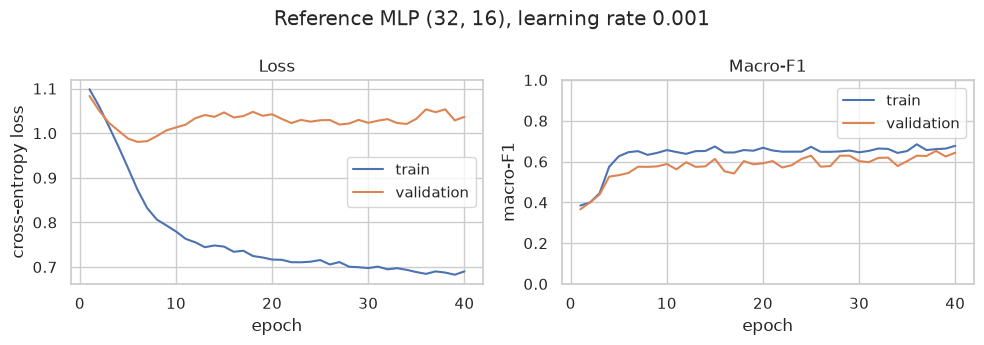

Read the curves this way: if the training line keeps improving while the validation line gets worse, the network is memorising the training samples.


In [9]:
reference_model, reference_history, reference_epoch = fit_mlp(
    hidden_dims=(32, 16),
    lr=1e-3,
    epochs=40,
)
print("Trainable parameters:", count_parameters(reference_model))
print("Best validation epoch:", reference_epoch)
print("Validation macro-F1 at that epoch:", round(reference_history["val_macro_f1"][reference_epoch - 1], 3))
plot_history(reference_history, "Reference MLP (32, 16), learning rate 0.001")
print("Read the curves this way: if the training line keeps improving while the validation line gets worse, the network is memorising the training samples.")


## Controlled experiments

Every run uses the same rows, the same seed, and the same preprocessing. Only the named setting changes.

1. **Learning rate:** `1e-4`, `1e-3`, `1e-2`, `1e-1`, on the reference architecture.
2. **Capacity:** a smaller net `(16,)` and a larger net `(64, 32)`, at the learning rate that won step 1. The reference `(32, 16)` is the middle size.
3. **Regularisation:** dropout `0.3`, weight decay `1e-3`, and early stopping with patience 8. These use the learning rate from step 1 and the capacity that won step 2.

The winner is the run with the highest validation macro-F1. Ties go to the lower validation loss, then to the smaller network.


Learning rate chosen from validation macro-F1: 0.01


,name,family,learning_rate,hidden_dims,dropout,weight_decay,patience,parameters,best_epoch,epochs_run,train_macro_f1,val_macro_f1,val_balanced_accuracy,val_loss
0,lr=0.0001,learning_rate,0.0001,"(32, 16)",0.0,0.0,none,3523,33,40,0.589722,0.529235,0.534799,0.998967
1,lr=0.001,learning_rate,0.0010,"(32, 16)",0.0,0.0,none,3523,38,40,0.661241,0.652047,0.649267,1.053479
2,lr=0.01,learning_rate,0.0100,"(32, 16)",0.0,0.0,none,3523,23,40,0.676300,0.711970,0.715812,1.151207
3,lr=0.1,learning_rate,0.1000,"(32, 16)",0.0,0.0,none,3523,33,40,0.613629,0.639896,0.654151,1.128627


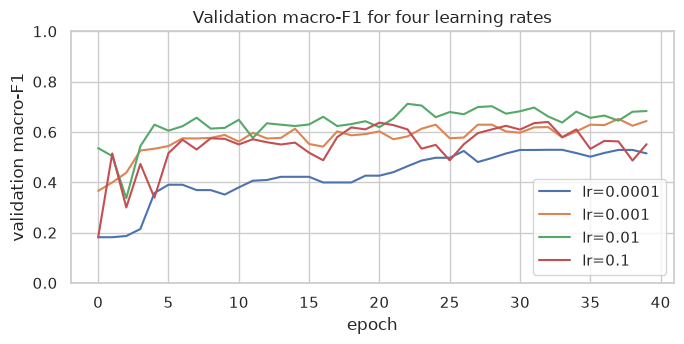

Capacity chosen from validation macro-F1: (16,)


,name,family,learning_rate,hidden_dims,dropout,weight_decay,patience,parameters,best_epoch,epochs_run,train_macro_f1,val_macro_f1,val_balanced_accuracy,val_loss
0,lr=0.01,learning_rate,0.01,"(32, 16)",0.0,0.0,none,3523,23,40,0.676300,0.711970,0.715812,1.151207
1,"small (16,)",capacity,0.01,"(16,)",0.0,0.0,none,1523,29,40,0.695543,0.719527,0.707875,1.134254
2,"large (64, 32)",capacity,0.01,"(64, 32)",0.0,0.0,none,8067,38,40,0.698318,0.712449,0.724664,1.136992


All runs, ranked by validation macro-F1. The test set has not been scored.


,name,family,learning_rate,hidden_dims,dropout,weight_decay,patience,parameters,best_epoch,epochs_run,train_macro_f1,val_macro_f1,val_balanced_accuracy,val_loss
8,weight decay 1e-3,regularisation,0.0100,"(16,)",0.0,0.001,none,1523,27,40,0.684658,0.742119,0.736569,1.037272
5,"small (16,)",capacity,0.0100,"(16,)",0.0,0.000,none,1523,29,40,0.695543,0.719527,0.707875,1.134254
9,"early stopping, patience 8",regularisation,0.0100,"(16,)",0.0,0.000,8,1523,29,37,0.695543,0.719527,0.707875,1.134254
6,"large (64, 32)",capacity,0.0100,"(64, 32)",0.0,0.000,none,8067,38,40,0.698318,0.712449,0.724664,1.136992
3,lr=0.01,learning_rate,0.0100,"(32, 16)",0.0,0.000,none,3523,23,40,0.676300,0.711970,0.715812,1.151207
7,dropout 0.3,regularisation,0.0100,"(16,)",0.3,0.000,none,1523,32,40,0.673989,0.685835,0.692002,1.140245
0,reference,reference,0.0010,"(32, 16)",0.0,0.000,none,3523,38,40,0.661241,0.652047,0.649267,1.053479
2,lr=0.001,learning_rate,0.0010,"(32, 16)",0.0,0.000,none,3523,38,40,0.661241,0.652047,0.649267,1.053479
4,lr=0.1,learning_rate,0.1000,"(32, 16)",0.0,0.000,none,3523,33,40,0.613629,0.639896,0.654151,1.128627
1,lr=0.0001,learning_rate,0.0001,"(32, 16)",0.0,0.000,none,3523,33,40,0.589722,0.529235,0.534799,0.998967


In [10]:
experiments = []

def record(name, family, model, history, best_epoch, lr, hidden_dims, dropout, weight_decay, patience):
    best_index = best_epoch - 1
    val_pred = predict_index(model, X_val_scaled)
    val_scores = classification_scores(y_val_idx, val_pred)
    experiments.append({
        "name": name,
        "family": family,
        "learning_rate": lr,
        "hidden_dims": str(hidden_dims),
        "dropout": dropout,
        "weight_decay": weight_decay,
        "patience": patience if patience is not None else "none",
        "parameters": count_parameters(model),
        "best_epoch": best_epoch,
        "epochs_run": len(history["train_loss"]),
        "train_macro_f1": history["train_macro_f1"][best_index],
        "val_macro_f1": val_scores["macro_f1"],
        "val_balanced_accuracy": val_scores["balanced_accuracy"],
        "val_loss": history["val_loss"][best_index],
        "model": model,
        "history": history,
    })

record(
    "reference", "reference", reference_model, reference_history, reference_epoch,
    1e-3, (32, 16), 0.0, 0.0, None,
)

learning_rates = [1e-4, 1e-3, 1e-2, 1e-1]
for learning_rate in learning_rates:
    # The reference run already covers learning rate 1e-3. Reuse it so the
    # comparison table does not contain two identical fits.
    if learning_rate == 1e-3:
        record(
            "lr=0.001", "learning_rate", reference_model, reference_history, reference_epoch,
            learning_rate, (32, 16), 0.0, 0.0, None,
        )
        continue
    model_lr, history_lr, epoch_lr = fit_mlp(hidden_dims=(32, 16), lr=learning_rate, epochs=40)
    record(
        f"lr={learning_rate:g}", "learning_rate", model_lr, history_lr, epoch_lr,
        learning_rate, (32, 16), 0.0, 0.0, None,
    )

lr_table = pd.DataFrame([row for row in experiments if row["family"] == "learning_rate"])
best_lr = float(lr_table.sort_values(["val_macro_f1", "val_loss"], ascending=[False, True]).iloc[0]["learning_rate"])
print("Learning rate chosen from validation macro-F1:", best_lr)
display(lr_table.drop(columns=["model", "history"]))

fig, axis = plt.subplots(figsize=(7, 3.6))
for learning_rate in learning_rates:
    history_lr = next(row["history"] for row in experiments if row["family"] == "learning_rate" and row["learning_rate"] == learning_rate)
    axis.plot(history_lr["val_macro_f1"], label=f"lr={learning_rate:g}")
axis.set_xlabel("epoch")
axis.set_ylabel("validation macro-F1")
axis.set_ylim(0, 1)
axis.set_title("Validation macro-F1 for four learning rates")
axis.legend()
fig.tight_layout()
plt.show()

capacities = {"small (16,)": (16,), "large (64, 32)": (64, 32)}
for capacity_name, hidden_dims in capacities.items():
    model_cap, history_cap, epoch_cap = fit_mlp(hidden_dims=hidden_dims, lr=best_lr, epochs=40)
    record(
        capacity_name, "capacity", model_cap, history_cap, epoch_cap,
        best_lr, hidden_dims, 0.0, 0.0, None,
    )

capacity_rows = [row for row in experiments if row["family"] in {"capacity", "reference"} or (row["family"] == "learning_rate" and row["learning_rate"] == best_lr and row["hidden_dims"] == "(32, 16)")]
# The middle capacity at the chosen learning rate is the fair third point.
capacity_table = pd.DataFrame([
    row for row in experiments
    if row["name"] in {"small (16,)", "large (64, 32)"} or (
        row["hidden_dims"] == "(32, 16)" and row["learning_rate"] == best_lr and row["dropout"] == 0.0 and row["weight_decay"] == 0.0 and row["patience"] == "none"
    )
]).drop_duplicates(subset=["hidden_dims"])
best_capacity_name = capacity_table.sort_values(["val_macro_f1", "val_loss"], ascending=[False, True]).iloc[0]["hidden_dims"]
best_hidden = eval(best_capacity_name)  # hidden_dims were stored with str(tuple)
print("Capacity chosen from validation macro-F1:", best_hidden)
display(capacity_table.drop(columns=["model", "history"]))

regularisers = [
    ("dropout 0.3", dict(dropout=0.3)),
    ("weight decay 1e-3", dict(weight_decay=1e-3)),
    ("early stopping, patience 8", dict(patience=8)),
]
for regulariser_name, options in regularisers:
    model_reg, history_reg, epoch_reg = fit_mlp(
        hidden_dims=best_hidden,
        lr=best_lr,
        epochs=40,
        **options,
    )
    record(
        regulariser_name, "regularisation", model_reg, history_reg, epoch_reg,
        best_lr, best_hidden, options.get("dropout", 0.0), options.get("weight_decay", 0.0), options.get("patience"),
    )

comparison = pd.DataFrame(experiments).drop(columns=["model", "history"])
comparison = comparison.sort_values(["val_macro_f1", "val_loss", "parameters"], ascending=[False, True, True])
print("All runs, ranked by validation macro-F1. The test set has not been scored.")
display(comparison)


## Choosing on validation, then scoring the test set once

The selected neural net is the top row of the table above. Logistic regression is the linear baseline; it has no extra settings to search. Both validation scores were known before this cell. The test predictions are created here for the first time.


Selected MLP: weight decay 1e-3
Settings: lr = 0.01 | hidden = (16,) | dropout = 0.0 | weight decay = 0.001 | patience = none


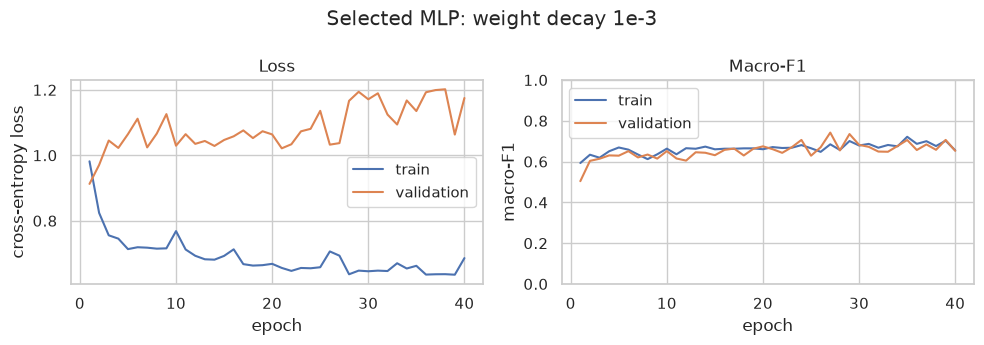

,model,split,accuracy,balanced_accuracy,macro_f1
0,logistic regression,validation,0.653333,0.660256,0.670479
1,logistic regression,test,0.605263,0.634079,0.613222
2,MLP (weight decay 1e-3),validation,0.733333,0.736569,0.742119
3,MLP (weight decay 1e-3),test,0.657895,0.675677,0.668580


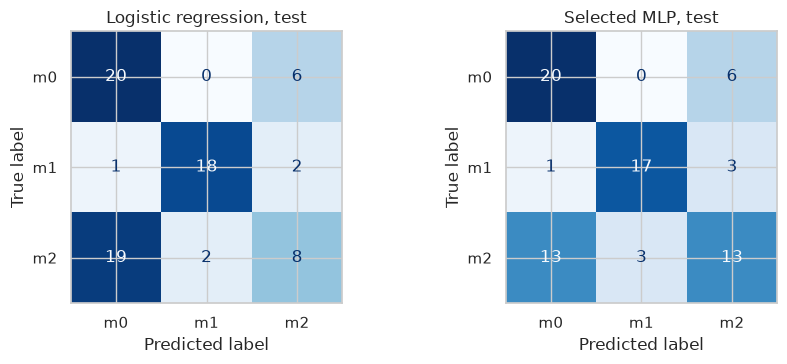

MLP classification report on the test set (precision, recall, F1 per class):
              precision    recall  f1-score   support

          m0      0.588     0.769     0.667        26
          m1      0.850     0.810     0.829        21
          m2      0.591     0.448     0.510        29

    accuracy                          0.658        76
   macro avg      0.676     0.676     0.669        76
weighted avg      0.662     0.658     0.652        76

Test samples, worst accuracy first:


,sample_group,true_type,objects,correct,accuracy
11,sample_group_056,m2,3,1,0.333333
16,sample_group_081,m2,13,5,0.384615
2,sample_group_015,m2,9,4,0.444444
0,sample_group_002,m1,2,1,0.500000
12,sample_group_064,m1,2,1,0.500000
13,sample_group_069,m0,2,1,0.500000
5,sample_group_026,m0,7,4,0.571429
7,sample_group_035,m1,3,2,0.666667
1,sample_group_012,m2,4,3,0.750000
8,sample_group_038,m1,4,3,0.750000


Mistaken pairs (true -> predicted):


objects
true_type predicted_type         
m0        m2                    6
m1        m0                    1
          m2                    3
m2        m0                   13
          m1                    3

In [11]:
ranked = sorted(
    experiments,
    key=lambda row: (row["val_macro_f1"], -row["val_loss"], -row["parameters"]),
    reverse=True,
)
selected = ranked[0]
selected_model = selected["model"]
selected_history = selected["history"]

print("Selected MLP:", selected["name"])
print("Settings: lr =", selected["learning_rate"], "| hidden =", selected["hidden_dims"],
      "| dropout =", selected["dropout"], "| weight decay =", selected["weight_decay"],
      "| patience =", selected["patience"])
plot_history(selected_history, f"Selected MLP: {selected['name']}")

logreg_test_pred = logreg.predict(X_test_scaled)
logreg_test_scores = classification_scores(y_test, logreg_test_pred)

mlp_test_index = predict_index(selected_model, X_test_scaled)
mlp_test_label = np.array(CLASS_NAMES)[mlp_test_index]
mlp_test_scores = classification_scores(y_test_idx, mlp_test_index)
mlp_val_scores = classification_scores(y_val_idx, predict_index(selected_model, X_val_scaled))

scoreboard = pd.DataFrame([
    {"model": "logistic regression", "split": "validation", **logreg_val_scores},
    {"model": "logistic regression", "split": "test", **logreg_test_scores},
    {"model": f"MLP ({selected['name']})", "split": "validation", **mlp_val_scores},
    {"model": f"MLP ({selected['name']})", "split": "test", **mlp_test_scores},
])
display(scoreboard)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, logreg_test_pred, labels=CLASS_NAMES, cmap="Blues", ax=axes[0], colorbar=False,
)
axes[0].set_title("Logistic regression, test")
ConfusionMatrixDisplay.from_predictions(
    y_test_idx, mlp_test_index, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[1], colorbar=False,
)
axes[1].set_title("Selected MLP, test")
fig.tight_layout()
plt.show()

print("MLP classification report on the test set (precision, recall, F1 per class):")
print(classification_report(y_test_idx, mlp_test_index, target_names=CLASS_NAMES, digits=3, zero_division=0))

# Each test group is a whole sample the model has never seen. Because every
# group has only one true cell type, a low group accuracy means that sample
# was given the wrong type, not a mix of labels inside one dish.
test_errors = pd.DataFrame({
    "sample_group": groups_test.to_numpy(),
    "true_type": y_test.to_numpy(),
    "predicted_type": mlp_test_label,
})
test_errors["correct"] = test_errors["true_type"] == test_errors["predicted_type"]
group_report = (
    test_errors.groupby(["sample_group", "true_type"], as_index=False)
    .agg(objects=("correct", "size"), correct=("correct", "sum"))
)
group_report["accuracy"] = group_report["correct"] / group_report["objects"]
group_report = group_report.sort_values(["accuracy", "objects"])
print("Test samples, worst accuracy first:")
display(group_report)

wrong = test_errors.loc[~test_errors["correct"]]
if len(wrong):
    print("Mistaken pairs (true -> predicted):")
    display(wrong.groupby(["true_type", "predicted_type"]).size().rename("objects").to_frame())
else:
    print("The selected MLP made no mistakes on the test objects.")

mlp_cm = confusion_matrix(y_test_idx, mlp_test_index, labels=[0, 1, 2])
logreg_cm = confusion_matrix(y_test, logreg_test_pred, labels=CLASS_NAMES)
